# Python orientado a objetos e SQL com SQLite: banco do monitoramento de idosos

**Grupo:** Dimitri Garcia (1682224), Henrique Santiago (16872729) e Henrique Guimarães Margarido (5797753).

**Contexto.** O projeto integrativo do grupo é uma rede de sensores para monitorar idosos em ILPIs (Instituições
de Longa Permanência para Idosos):
- **em cada quarto**, um hub com ESP32 lê as portas (quarto e banheiro), a presença (PIR) e a temperatura;
- **cada idoso** usa uma pulseira que detecta quedas;
- **os alertas** (queda, saída noturna, banheiro prolongado...) chegam por MQTT e avisam os cuidadores.

Este notebook modela esse banco em SQLite: tabelas com chaves primárias e estrangeiras, classes Python para as
entidades, DAOs com CRUD em SQL parametrizado, dados fictícios com o Faker e consultas com `JOIN`. Ele segue o
exemplo da aula (Singleton, DAOs, SQL explícito, sem Pandas nem SQLAlchemy), com duas diferenças:
- **os ids são gerados pelo banco** e devolvidos com `INSERT ... RETURNING`, como no PostgreSQL que o projeto
  vai usar no fim;
- **as tabelas são `STRICT`**: o SQLite passa a recusar um texto numa coluna `INTEGER`.

O notebook roda do início ao fim sem nenhum arquivo externo: ele mesmo cria o `projeto.db`.

## Modelo entidade-relacionamento

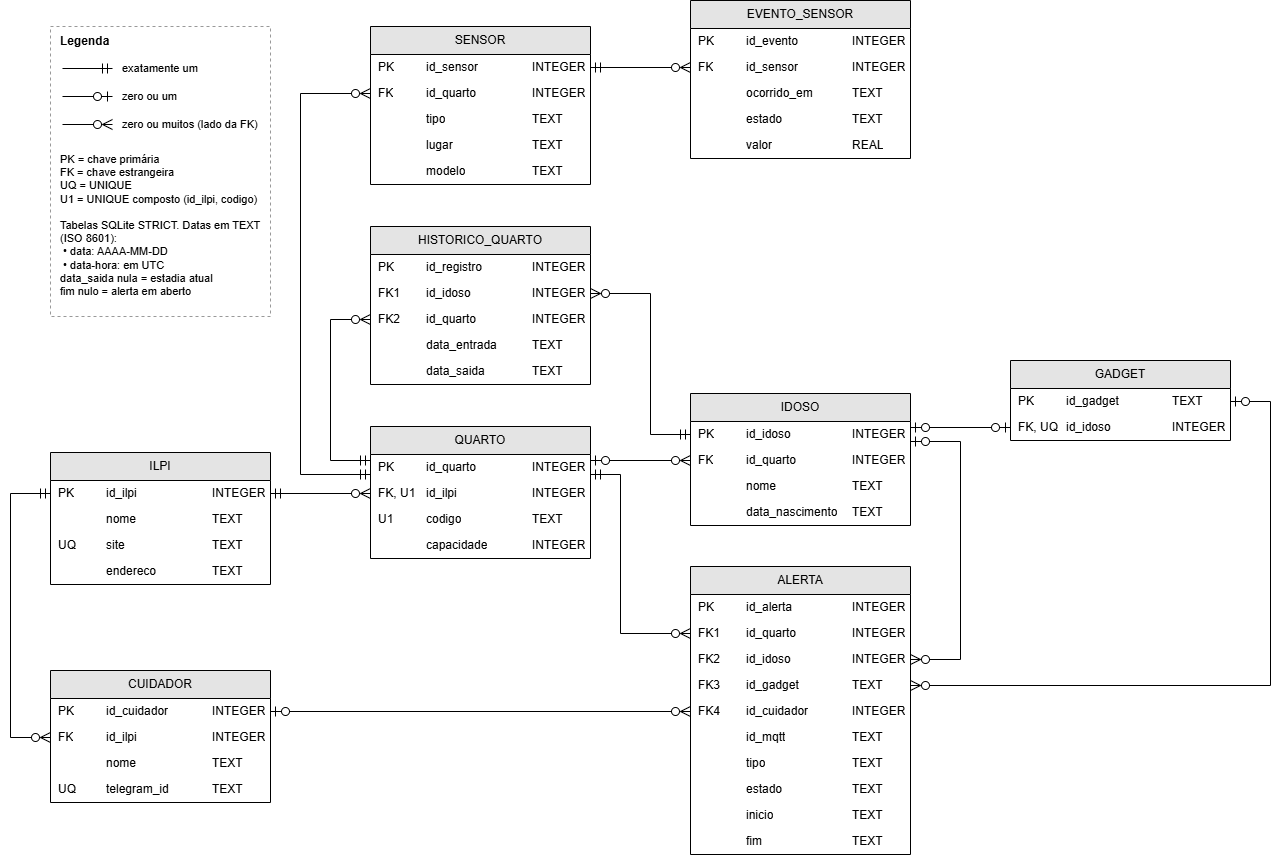

| Tabela | Chave primária | Chaves estrangeiras | Observação |
|---|---|---|---|
| `ilpi` | `id_ilpi` | — | `site` é o `<site>` dos tópicos MQTT `idoso/<site>/<quarto>/...` |
| `cuidador` | `id_cuidador` | `id_ilpi` | `telegram_id` é texto: é identificador, não número |
| `quarto` | `id_quarto` | `id_ilpi` | `codigo` é o `<quarto>` do tópico; `UNIQUE(id_ilpi, codigo)` |
| `idoso` | `id_idoso` | `id_quarto` (quarto atual) | a idade não é gravada: é calculada da `data_nascimento` |
| `gadget` | `id_gadget` (MAC) | `id_idoso` (`UNIQUE`) | sem idoso = pulseira reserva |
| `sensor` | `id_sensor` | `id_quarto` | `tipo`: porta, presença ou temperatura |
| `evento_sensor` | `id_evento` | `id_sensor` | estado (porta, presença) ou valor (°C) |
| `historico_quarto` | `id_registro` | `id_idoso`, `id_quarto` | períodos `[data_entrada, data_saida)`; sem saída = quarto atual |
| `alerta` | `id_alerta` | `id_quarto`, `id_idoso`, `id_gadget`, `id_cuidador` | `estado`: ativo, resolvido ou cancelado |

**Datas.** O SQLite não tem tipo de data, então as datas ficam em `TEXT`, sempre no padrão ISO 8601:
- datas, como `'1940-05-17'`;
- instantes em UTC, como `'2026-11-01 03:00:00'`, o mesmo formato do `CURRENT_TIMESTAMP`.

Esse formato ordena certo como texto e funciona com `date()` e `julianday()`. No Python, viram `date` e
`datetime` com fuso UTC; o DAO faz a conversão.

## 1. Importações e conexão com o SQLite (Singleton)

`BancoSQLite()` sempre devolve a mesma instância enquanto a conexão está aberta. Assim, todos os DAOs
compartilham uma única conexão. No SQLite, as chaves estrangeiras vêm **desligadas**: o
`PRAGMA foreign_keys = ON` precisa ser executado em toda conexão nova.

In [1]:
import sqlite3
from pathlib import Path

ARQUIVO_BANCO = Path("projeto.db")


class BancoSQLite:
    """`BancoSQLite()` devolve sempre a mesma instância enquanto a conexão estiver aberta."""

    _instancia = None

    def __new__(cls, arquivo=ARQUIVO_BANCO):
        if cls._instancia is None:
            banco = super().__new__(cls)
            banco.arquivo = Path(arquivo)
            banco.conexao = sqlite3.connect(banco.arquivo)
            banco.conexao.row_factory = sqlite3.Row
            # No SQLite as chaves estrangeiras vêm desligadas: é preciso ligar em toda conexão.
            banco.conexao.execute("PRAGMA foreign_keys = ON")
            cls._instancia = banco
        return cls._instancia

    def fechar(self):
        self.conexao.close()
        type(self)._instancia = None

In [2]:
existia_antes = ARQUIVO_BANCO.exists()
banco = BancoSQLite()
conexao = banco.conexao

versao = conexao.execute("SELECT sqlite_version() AS versao").fetchone()["versao"]
print("Arquivo já existia?", existia_antes)
print("Arquivo existe agora?", ARQUIVO_BANCO.exists())
print("SQLite:", versao)
print("Mesma conexão?", conexao is BancoSQLite().conexao)
print("Chaves estrangeiras ligadas?", conexao.execute("PRAGMA foreign_keys").fetchone()[0] == 1)

assert banco is BancoSQLite()
assert conexao is BancoSQLite().conexao

Arquivo já existia? True
Arquivo existe agora? True
SQLite: 3.53.4
Mesma conexão? True
Chaves estrangeiras ligadas? True


## 2. Criação das tabelas

Cada `CREATE TABLE` define a chave primária, as chaves estrangeiras e as regras do domínio:
- `CHECK` para os valores possíveis e para o formato das datas;
- `UNIQUE` para o que não pode se repetir;
- um índice parcial `UNIQUE ... WHERE data_saida IS NULL`, que garante no máximo um quarto atual por idoso.

`ON DELETE` diz o que acontece com quem referencia uma linha apagada:
- **`SET NULL`:** o alerta continua no histórico se o idoso for excluído;
- **`CASCADE`:** as leituras de um sensor vão junto com ele;
- **o padrão** bloqueia a exclusão, por exemplo de um quarto ocupado.

**Para repetir a atividade:** `criar_tabelas` apaga e recria as tabelas. Numa aplicação real, os dados não
seriam apagados assim.

In [3]:
SQL_ILPI = """
CREATE TABLE IF NOT EXISTS ilpi (
    id_ilpi  INTEGER PRIMARY KEY,
    nome     TEXT NOT NULL,
    site     TEXT NOT NULL UNIQUE,          -- o <site> do tópico MQTT idoso/<site>/<quarto>/...
    endereco TEXT NOT NULL
) STRICT
"""

SQL_CUIDADOR = """
CREATE TABLE IF NOT EXISTS cuidador (
    id_cuidador INTEGER PRIMARY KEY,
    id_ilpi     INTEGER NOT NULL,
    nome        TEXT NOT NULL,
    telegram_id TEXT UNIQUE,                -- identificador, não número: fica TEXT
    FOREIGN KEY (id_ilpi) REFERENCES ilpi (id_ilpi)
) STRICT
"""

SQL_QUARTO = """
CREATE TABLE IF NOT EXISTS quarto (
    id_quarto  INTEGER PRIMARY KEY,
    id_ilpi    INTEGER NOT NULL,
    codigo     TEXT NOT NULL,               -- o <quarto> do tópico MQTT, ex.: 'quarto101'
    capacidade INTEGER NOT NULL DEFAULT 1 CHECK (capacidade > 0),
    UNIQUE (id_ilpi, codigo),               -- duas ILPIs podem ter um 'quarto101'
    FOREIGN KEY (id_ilpi) REFERENCES ilpi (id_ilpi)
) STRICT
"""

SQL_IDOSO = """
CREATE TABLE IF NOT EXISTS idoso (
    id_idoso        INTEGER PRIMARY KEY,
    nome            TEXT NOT NULL,
    data_nascimento TEXT NOT NULL CHECK (data_nascimento IS date(data_nascimento)),
    id_quarto       INTEGER,                -- quarto atual (NULL: sem quarto)
    FOREIGN KEY (id_quarto) REFERENCES quarto (id_quarto)
) STRICT
"""

SQL_GADGET = """
CREATE TABLE IF NOT EXISTS gadget (
    id_gadget TEXT NOT NULL PRIMARY KEY     -- 3 últimos bytes do MAC em hexadecimal, ex.: 'a1b2c3'
              CHECK (length(id_gadget) = 6 AND id_gadget NOT GLOB '*[^0-9a-f]*'),
    id_idoso  INTEGER UNIQUE,               -- uma pulseira por idoso; NULL = pulseira reserva
    FOREIGN KEY (id_idoso) REFERENCES idoso (id_idoso) ON DELETE SET NULL
) STRICT
"""

SQL_SENSOR = """
CREATE TABLE IF NOT EXISTS sensor (
    id_sensor INTEGER PRIMARY KEY,
    id_quarto INTEGER NOT NULL,
    tipo      TEXT NOT NULL CHECK (tipo IN ('porta', 'presenca', 'temperatura')),
    lugar     TEXT NOT NULL,                -- ex.: porta do 'quarto' ou do 'banheiro'
    modelo    TEXT NOT NULL,                -- MC-38, HC-SR501, LM35DZ
    UNIQUE (id_quarto, tipo, lugar),
    FOREIGN KEY (id_quarto) REFERENCES quarto (id_quarto)
) STRICT
"""

SQL_EVENTO_SENSOR = """
CREATE TABLE IF NOT EXISTS evento_sensor (
    id_evento   INTEGER PRIMARY KEY,
    id_sensor   INTEGER NOT NULL,
    ocorrido_em TEXT NOT NULL DEFAULT CURRENT_TIMESTAMP
                CHECK (ocorrido_em IS datetime(ocorrido_em)),
    estado      TEXT,                       -- 'aberta'/'fechada', 'detectada'/'livre'
    valor       REAL,                       -- temperatura em °C
    CHECK (estado IS NOT NULL OR valor IS NOT NULL),
    FOREIGN KEY (id_sensor) REFERENCES sensor (id_sensor) ON DELETE CASCADE
) STRICT
"""

SQL_HISTORICO_QUARTO = """
CREATE TABLE IF NOT EXISTS historico_quarto (
    id_registro  INTEGER PRIMARY KEY,
    id_idoso     INTEGER NOT NULL,
    id_quarto    INTEGER NOT NULL,
    data_entrada TEXT NOT NULL CHECK (data_entrada IS date(data_entrada)),
    data_saida   TEXT CHECK (data_saida IS date(data_saida)),   -- NULL: ainda está no quarto
    CHECK (data_saida IS NULL OR data_saida >= data_entrada),
    FOREIGN KEY (id_idoso) REFERENCES idoso (id_idoso) ON DELETE CASCADE,
    FOREIGN KEY (id_quarto) REFERENCES quarto (id_quarto)
) STRICT
"""

SQL_ALERTA = """
CREATE TABLE IF NOT EXISTS alerta (
    id_alerta   INTEGER PRIMARY KEY,
    id_mqtt     TEXT NOT NULL,              -- o "id" do payload MQTT do alerta
    tipo        TEXT NOT NULL CHECK (tipo IN ('queda', 'saida_noturna', 'banheiro_prolongado',
                    'inatividade', 'temperatura', 'vestivel_offline', 'bateria_baixa')),
    estado      TEXT NOT NULL DEFAULT 'ativo' CHECK (estado IN ('ativo', 'resolvido', 'cancelado')),
    inicio      TEXT NOT NULL CHECK (inicio IS datetime(inicio)),
    fim         TEXT CHECK (fim IS datetime(fim)),
    id_quarto   INTEGER NOT NULL,
    id_idoso    INTEGER,
    id_gadget   TEXT,
    id_cuidador INTEGER,                    -- quem atendeu
    UNIQUE (id_quarto, id_mqtt),            -- 'temperatura-<ts>' pode se repetir em outro quarto
    CHECK ((estado = 'ativo') = (fim IS NULL)),
    CHECK (fim IS NULL OR fim >= inicio),
    FOREIGN KEY (id_quarto) REFERENCES quarto (id_quarto),
    FOREIGN KEY (id_idoso) REFERENCES idoso (id_idoso) ON DELETE SET NULL,
    FOREIGN KEY (id_gadget) REFERENCES gadget (id_gadget) ON DELETE SET NULL,
    FOREIGN KEY (id_cuidador) REFERENCES cuidador (id_cuidador) ON DELETE SET NULL
) STRICT
"""

SQL_INDICES = [
    # Consultas por sensor ou quarto em ordem de tempo.
    "CREATE INDEX IF NOT EXISTS idx_evento_sensor_tempo ON evento_sensor (id_sensor, ocorrido_em)",
    "CREATE INDEX IF NOT EXISTS idx_alerta_quarto_inicio ON alerta (id_quarto, inicio)",
    # Índice parcial: no máximo um período em aberto (quarto atual) por idoso.
    """CREATE UNIQUE INDEX IF NOT EXISTS idx_historico_quarto_atual
       ON historico_quarto (id_idoso) WHERE data_saida IS NULL""",
]

# Ordem em que as tabelas dependem umas das outras (as referenciadas antes).
TABELAS = ["ilpi", "cuidador", "quarto", "idoso", "gadget", "sensor", "evento_sensor",
           "historico_quarto", "alerta"]
SQL_TABELAS = [SQL_ILPI, SQL_CUIDADOR, SQL_QUARTO, SQL_IDOSO, SQL_GADGET, SQL_SENSOR, SQL_EVENTO_SENSOR,
               SQL_HISTORICO_QUARTO, SQL_ALERTA]


def criar_tabelas(conexao, recriar=True):
    """Cria as tabelas e os índices. Com recriar=True, apaga antes (só para a atividade poder rodar de novo)."""
    if recriar:
        for tabela in reversed(TABELAS):   # as que referenciam primeiro; os nomes vêm da lista fixa acima
            conexao.execute(f"DROP TABLE IF EXISTS {tabela}")
    for sql in SQL_TABELAS + SQL_INDICES:
        conexao.execute(sql)
    conexao.commit()

In [4]:
criar_tabelas(conexao, recriar=True)
sql = """
SELECT type, name
FROM sqlite_master
WHERE name NOT LIKE 'sqlite_%'
ORDER BY type DESC, name
"""
for linha in conexao.execute(sql).fetchall():
    print(f"{linha['type']:6} {linha['name']}")

table  alerta
table  cuidador
table  evento_sensor
table  gadget
table  historico_quarto
table  idoso
table  ilpi
table  quarto
table  sensor
index  idx_alerta_quarto_inicio
index  idx_evento_sensor_tempo
index  idx_historico_quarto_atual


**Diagnóstico:** as chaves estrangeiras de cada tabela, lidas do catálogo do próprio SQLite.

In [5]:
# PRAGMA não aceita parâmetro (?); os nomes vêm da lista fixa TABELAS, não de entrada externa.
for tabela in TABELAS:
    for fk in conexao.execute(f"PRAGMA foreign_key_list({tabela})").fetchall():
        origem, destino = f"{tabela}.{fk['from']}", f"{fk['table']}.{fk['to']}"
        print(f"{origem:28} → {destino:22} ON DELETE {fk['on_delete']}")

cuidador.id_ilpi             → ilpi.id_ilpi           ON DELETE NO ACTION
quarto.id_ilpi               → ilpi.id_ilpi           ON DELETE NO ACTION
idoso.id_quarto              → quarto.id_quarto       ON DELETE NO ACTION
gadget.id_idoso              → idoso.id_idoso         ON DELETE SET NULL
sensor.id_quarto             → quarto.id_quarto       ON DELETE NO ACTION
evento_sensor.id_sensor      → sensor.id_sensor       ON DELETE CASCADE
historico_quarto.id_quarto   → quarto.id_quarto       ON DELETE NO ACTION
historico_quarto.id_idoso    → idoso.id_idoso         ON DELETE CASCADE
alerta.id_cuidador           → cuidador.id_cuidador   ON DELETE SET NULL
alerta.id_gadget             → gadget.id_gadget       ON DELETE SET NULL
alerta.id_idoso              → idoso.id_idoso         ON DELETE SET NULL
alerta.id_quarto             → quarto.id_quarto       ON DELETE NO ACTION


## 3. Classes orientadas a objetos

As classes representam as entidades. As relações são **objetos**: um `Quarto` guarda a sua `ILPI`, e um
`Alerta` guarda o seu `Quarto`, o `Idoso` e a `Gadget`. No banco elas viram chaves estrangeiras, e quem faz a
tradução são os DAOs.

O id começa como `None` e só o DAO o define, com o valor gerado pelo banco. Depois ele não muda: é uma
propriedade somente leitura.

Primeiro, as funções de conversão de datas e horários usadas pelos DAOs.

In [6]:
from datetime import date, datetime, timezone

# Formato dos instantes no banco: o mesmo do CURRENT_TIMESTAMP do SQLite, sempre em UTC.
FORMATO_INSTANTE = "%Y-%m-%d %H:%M:%S"


def instante_para_texto(momento: datetime | None) -> str | None:
    """datetime com fuso → 'AAAA-MM-DD HH:MM:SS' em UTC (o que vai para o banco)."""
    if momento is None:
        return None
    if momento.tzinfo is None:
        raise ValueError("use datetime com fuso horário, por exemplo timezone.utc")
    return momento.astimezone(timezone.utc).strftime(FORMATO_INSTANTE)


def texto_para_instante(texto: str | None) -> datetime | None:
    """'AAAA-MM-DD HH:MM:SS' (UTC) → datetime com fuso UTC (o que volta do banco)."""
    if texto is None:
        return None
    return datetime.strptime(texto, FORMATO_INSTANTE).replace(tzinfo=timezone.utc)


def data_para_texto(dia: date | None) -> str | None:
    return None if dia is None else dia.isoformat()


def texto_para_data(texto: str | None) -> date | None:
    return None if texto is None else date.fromisoformat(texto)

`Entidade` é a base de todas as classes. `Pessoa` (abstrata) é a base de `Idoso` e `Cuidador`.

In [7]:
from abc import ABC, abstractmethod


class Entidade(ABC):
    """Base de todas as entidades: guarda o id, que só o DAO define, uma única vez."""

    def __init__(self, id_entidade=None):
        self._id = id_entidade

    def _definir_id(self, valor):
        if self._id is not None:
            raise ValueError(f"{type(self).__name__} já tem id ({self._id})")
        self._id = valor

    @abstractmethod
    def to_dict(self) -> dict:
        pass


class Pessoa(Entidade):
    """Idosos e cuidadores são pessoas: têm um nome."""

    def __init__(self, nome: str, id_pessoa: int | None = None):
        super().__init__(id_pessoa)
        self.nome = nome

    def __repr__(self):
        return f"{type(self).__name__}(id={self._id}, nome={self.nome!r})"

In [8]:
class ILPI(Entidade):
    def __init__(self, nome: str, site: str, endereco: str, id_ilpi: int | None = None):
        super().__init__(id_ilpi)
        self.nome = nome
        self.site = site
        self.endereco = endereco

    @property
    def id_ilpi(self) -> int | None:
        return self._id

    def to_dict(self) -> dict:
        return {"id_ilpi": self.id_ilpi, "nome": self.nome, "site": self.site, "endereco": self.endereco}

    def __repr__(self):
        return f"ILPI(id={self.id_ilpi}, site={self.site!r})"


class Quarto(Entidade):
    def __init__(self, ilpi: ILPI, codigo: str, capacidade: int = 1, id_quarto: int | None = None):
        super().__init__(id_quarto)
        if capacidade < 1:
            raise ValueError("a capacidade do quarto deve ser de pelo menos 1")
        self.ilpi = ilpi
        self.codigo = codigo
        self.capacidade = capacidade

    @property
    def id_quarto(self) -> int | None:
        return self._id

    @property
    def topico(self) -> str:
        """Prefixo dos tópicos MQTT que o hub deste quarto publica."""
        return f"idoso/{self.ilpi.site}/{self.codigo}"

    def to_dict(self) -> dict:
        return {"id_quarto": self.id_quarto, "id_ilpi": self.ilpi.id_ilpi, "codigo": self.codigo,
                "capacidade": self.capacidade}

    def __repr__(self):
        return f"Quarto(id={self.id_quarto}, topico={self.topico!r})"


TIPOS_SENSOR = ("porta", "presenca", "temperatura")   # os mesmos do CHECK da tabela sensor


class Sensor(Entidade):
    def __init__(self, quarto: Quarto, tipo: str, lugar: str, modelo: str, id_sensor: int | None = None):
        super().__init__(id_sensor)
        if tipo not in TIPOS_SENSOR:
            raise ValueError(f"tipo de sensor desconhecido: {tipo!r}")
        self.quarto = quarto
        self.tipo = tipo
        self.lugar = lugar
        self.modelo = modelo

    @property
    def id_sensor(self) -> int | None:
        return self._id

    @property
    def topico(self) -> str:
        """Tópico MQTT do sensor, como em docs/protocolo.md do projeto."""
        if self.tipo == "porta":
            return f"{self.quarto.topico}/porta/{self.lugar}"
        return f"{self.quarto.topico}/{self.tipo}"

    def to_dict(self) -> dict:
        return {"id_sensor": self.id_sensor, "id_quarto": self.quarto.id_quarto, "tipo": self.tipo,
                "lugar": self.lugar, "modelo": self.modelo}

    def __repr__(self):
        return f"Sensor(id={self.id_sensor}, topico={self.topico!r})"


class EventoSensor(Entidade):
    """Uma leitura (temperatura) ou mudança de estado (porta, presença) de um sensor."""

    def __init__(self, sensor: Sensor, ocorrido_em: datetime, estado: str | None = None,
                 valor: float | None = None, id_evento: int | None = None):
        super().__init__(id_evento)
        if estado is None and valor is None:
            raise ValueError("o evento precisa de um estado ou de um valor")
        self.sensor = sensor
        self.ocorrido_em = ocorrido_em
        self.estado = estado
        self.valor = valor

    @property
    def id_evento(self) -> int | None:
        return self._id

    def to_dict(self) -> dict:
        return {"id_evento": self.id_evento, "id_sensor": self.sensor.id_sensor,
                "ocorrido_em": instante_para_texto(self.ocorrido_em), "estado": self.estado,
                "valor": self.valor}

    def __repr__(self):
        leitura = self.estado if self.estado is not None else f"{self.valor} °C"
        return f"EventoSensor(id={self.id_evento}, sensor={self.sensor.id_sensor}, {leitura})"

In [9]:
class Idoso(Pessoa):
    def __init__(self, nome: str, data_nascimento: date, quarto: Quarto | None = None,
                 id_idoso: int | None = None):
        super().__init__(nome, id_idoso)
        self.data_nascimento = data_nascimento
        self.quarto = quarto

    @property
    def id_idoso(self) -> int | None:
        return self._id

    def idade_em(self, dia: date) -> int:
        """Idade calculada (não gravada no banco), como o 'aprovado' do exemplo da aula."""
        aniversario_ja_passou = (dia.month, dia.day) >= (self.data_nascimento.month, self.data_nascimento.day)
        return dia.year - self.data_nascimento.year - (0 if aniversario_ja_passou else 1)

    @property
    def idade(self) -> int:
        return self.idade_em(date.today())

    def to_dict(self) -> dict:
        return {"id_idoso": self.id_idoso, "nome": self.nome,
                "data_nascimento": data_para_texto(self.data_nascimento),
                "id_quarto": self.quarto.id_quarto if self.quarto else None}


class Cuidador(Pessoa):
    def __init__(self, nome: str, ilpi: ILPI, telegram_id: str | None = None, id_cuidador: int | None = None):
        super().__init__(nome, id_cuidador)
        self.ilpi = ilpi
        self.telegram_id = telegram_id

    @property
    def id_cuidador(self) -> int | None:
        return self._id

    def to_dict(self) -> dict:
        return {"id_cuidador": self.id_cuidador, "id_ilpi": self.ilpi.id_ilpi, "nome": self.nome,
                "telegram_id": self.telegram_id}

In [10]:
class Gadget(Entidade):
    """A pulseira. O id vem de fora (3 últimos bytes do MAC), então já nasce definido."""

    def __init__(self, id_gadget: str, idoso: Idoso | None = None):
        if len(id_gadget) != 6 or any(c not in "0123456789abcdef" for c in id_gadget):
            raise ValueError(f"id de pulseira inválido: {id_gadget!r} (6 dígitos hexadecimais minúsculos)")
        super().__init__(id_gadget)
        self.idoso = idoso

    @property
    def id_gadget(self) -> str:
        return self._id

    def to_dict(self) -> dict:
        return {"id_gadget": self.id_gadget, "id_idoso": self.idoso.id_idoso if self.idoso else None}

    def __repr__(self):
        dono = self.idoso.nome if self.idoso else "reserva"
        return f"Gadget(id={self.id_gadget!r}, {dono})"


class HistoricoQuarto(Entidade):
    """Período em que um idoso ocupou um quarto: [data_entrada, data_saida). Sem saída = quarto atual."""

    def __init__(self, idoso: Idoso, quarto: Quarto, data_entrada: date, data_saida: date | None = None,
                 id_registro: int | None = None):
        super().__init__(id_registro)
        if data_saida is not None and data_saida < data_entrada:
            raise ValueError("a saída não pode ser antes da entrada")
        self.idoso = idoso
        self.quarto = quarto
        self.data_entrada = data_entrada
        self.data_saida = data_saida

    @property
    def id_registro(self) -> int | None:
        return self._id

    @property
    def atual(self) -> bool:
        return self.data_saida is None

    def contem(self, dia: date) -> bool:
        return self.data_entrada <= dia and (self.data_saida is None or dia < self.data_saida)

    def to_dict(self) -> dict:
        return {"id_registro": self.id_registro, "id_idoso": self.idoso.id_idoso,
                "id_quarto": self.quarto.id_quarto, "data_entrada": data_para_texto(self.data_entrada),
                "data_saida": data_para_texto(self.data_saida)}

    def __repr__(self):
        fim = self.data_saida or "hoje"
        return f"HistoricoQuarto({self.idoso.nome!r} em {self.quarto.codigo}, {self.data_entrada} a {fim})"


TIPOS_ALERTA = ("queda", "saida_noturna", "banheiro_prolongado", "inatividade", "temperatura",
                "vestivel_offline", "bateria_baixa")            # os mesmos do CHECK da tabela alerta
ESTADOS_ALERTA = ("ativo", "resolvido", "cancelado")


class Alerta(Entidade):
    def __init__(self, id_mqtt: str, tipo: str, quarto: Quarto, inicio: datetime,
                 idoso: Idoso | None = None, gadget: Gadget | None = None, estado: str = "ativo",
                 fim: datetime | None = None, cuidador: Cuidador | None = None, id_alerta: int | None = None):
        super().__init__(id_alerta)
        if tipo not in TIPOS_ALERTA:
            raise ValueError(f"tipo de alerta desconhecido: {tipo!r}")
        if estado not in ESTADOS_ALERTA:
            raise ValueError(f"estado de alerta desconhecido: {estado!r}")
        self.id_mqtt = id_mqtt
        self.tipo = tipo
        self.quarto = quarto
        self.inicio = inicio
        self.idoso = idoso
        self.gadget = gadget
        self.estado = estado
        self.fim = fim
        self.cuidador = cuidador

    @property
    def id_alerta(self) -> int | None:
        return self._id

    @property
    def ativo(self) -> bool:
        return self.estado == "ativo"

    @property
    def duracao(self):
        """Do início ao fim (timedelta), ou None enquanto estiver ativo."""
        return None if self.fim is None else self.fim - self.inicio

    def resolver(self, cuidador: Cuidador, fim: datetime):
        """O cuidador atendeu: o alerta deixa de estar ativo."""
        if not self.ativo:
            raise ValueError(f"o alerta já está {self.estado}")
        if fim < self.inicio:
            raise ValueError("o fim não pode ser antes do início")
        self.estado, self.fim, self.cuidador = "resolvido", fim, cuidador

    def to_dict(self) -> dict:
        return {"id_alerta": self.id_alerta, "id_mqtt": self.id_mqtt, "tipo": self.tipo, "estado": self.estado,
                "inicio": instante_para_texto(self.inicio), "fim": instante_para_texto(self.fim),
                "id_quarto": self.quarto.id_quarto, "id_idoso": self.idoso.id_idoso if self.idoso else None,
                "id_gadget": self.gadget.id_gadget if self.gadget else None,
                "id_cuidador": self.cuidador.id_cuidador if self.cuidador else None}

    def __repr__(self):
        return f"Alerta(id={self.id_alerta}, {self.tipo}, {self.estado}, {self.quarto.codigo})"

### Teste dos objetos, ainda sem banco

Os objetos funcionam na memória. A idade do idoso e a duração do alerta são calculadas, não gravadas.
`resolver()` muda o estado do alerta, e as classes validam os valores antes de chegar ao banco.

In [11]:
ilpi_exemplo = ILPI("ILPI Exemplo", "exemplo", "Rua A, 1")
quarto_exemplo = Quarto(ilpi_exemplo, "quarto101", capacidade=2)
idoso_exemplo = Idoso("Ana Souza", date(1940, 5, 17), quarto_exemplo)
pulseira_exemplo = Gadget("a1b2c3", idoso_exemplo)
sensor_exemplo = Sensor(quarto_exemplo, "porta", "banheiro", "MC-38")
cuidador_exemplo = Cuidador("Beatriz Lima", ilpi_exemplo, "123456789")
alerta_exemplo = Alerta("a1b2c3-1", "queda", quarto_exemplo, datetime(2026, 11, 1, 3, 0, tzinfo=timezone.utc),
                        idoso_exemplo, pulseira_exemplo)

print(idoso_exemplo, "| idade em 01/11/2026:", idoso_exemplo.idade_em(date(2026, 11, 1)))
print(pulseira_exemplo)
print("Tópico MQTT do sensor:", sensor_exemplo.topico)
print(alerta_exemplo, alerta_exemplo.to_dict())

alerta_exemplo.resolver(cuidador_exemplo, datetime(2026, 11, 1, 3, 12, tzinfo=timezone.utc))
print("Depois de resolver:", alerta_exemplo, "| duração:", alerta_exemplo.duracao)

try:
    Sensor(quarto_exemplo, "fumaca", "quarto", "?")
except ValueError as erro:
    print("Validação no Python:", erro)

assert idoso_exemplo.id_idoso is None          # ainda não foi gravado: o banco é que gera o id
assert idoso_exemplo.idade_em(date(2026, 11, 1)) == 86
assert alerta_exemplo.estado == "resolvido" and not alerta_exemplo.ativo

Idoso(id=None, nome='Ana Souza') | idade em 01/11/2026: 86
Gadget(id='a1b2c3', Ana Souza)
Tópico MQTT do sensor: idoso/exemplo/quarto101/porta/banheiro
Alerta(id=None, queda, ativo, quarto101) {'id_alerta': None, 'id_mqtt': 'a1b2c3-1', 'tipo': 'queda', 'estado': 'ativo', 'inicio': '2026-11-01 03:00:00', 'fim': None, 'id_quarto': None, 'id_idoso': None, 'id_gadget': 'a1b2c3', 'id_cuidador': None}
Depois de resolver: Alerta(id=None, queda, resolvido, quarto101) | duração: 0:12:00
Validação no Python: tipo de sensor desconhecido: 'fumaca'


## 4. Classes DAO (Data Access Object)

Cada DAO grava e lê uma entidade com SQL escrito explicitamente:
- `inserir` (`INSERT ... RETURNING`), `buscar`, `listar`, `atualizar` (`UPDATE`) e `excluir` (`DELETE`);
- `_da_linha`, que monta o objeto a partir de uma linha do banco, buscando os objetos relacionados.

Todo valor externo entra por **parâmetro** (`?` ou `:nome`): os valores vão separados do SQL e nunca são
interpretados como comando. As consultas com `JOIN` devolvem dicionários, prontos para mostrar.

In [12]:
class DAO:
    """Base dos DAOs: todos usam a mesma conexão, a do Singleton."""

    def __init__(self):
        self.conexao = BancoSQLite().conexao

    def _inserir_e_obter_id(self, sql, valores):
        """Executa um INSERT ... RETURNING, confirma e devolve o id gerado pelo banco."""
        linhas = self.conexao.execute(sql, valores).fetchall()   # termina o comando antes do commit
        self.conexao.commit()
        return linhas[0][0]

    def _alterar(self, sql, valores):
        """Executa um UPDATE ou DELETE, confirma e devolve quantas linhas mudaram."""
        cursor = self.conexao.execute(sql, valores)
        self.conexao.commit()
        return cursor.rowcount

In [13]:
class ILPIDAO(DAO):
    @staticmethod
    def _da_linha(linha):
        return ILPI(linha["nome"], linha["site"], linha["endereco"], id_ilpi=linha["id_ilpi"])

    def inserir(self, ilpi: ILPI) -> int:
        sql = """
        INSERT INTO ilpi (nome, site, endereco)
        VALUES (?, ?, ?)
        RETURNING id_ilpi
        """
        ilpi._definir_id(self._inserir_e_obter_id(sql, (ilpi.nome, ilpi.site, ilpi.endereco)))
        return ilpi.id_ilpi

    def buscar(self, id_ilpi: int):
        sql = "SELECT * FROM ilpi WHERE id_ilpi = ?"
        linha = self.conexao.execute(sql, (id_ilpi,)).fetchone()
        return None if linha is None else self._da_linha(linha)

    def buscar_por_site(self, site: str):
        sql = "SELECT * FROM ilpi WHERE site = ?"
        linha = self.conexao.execute(sql, (site,)).fetchone()
        return None if linha is None else self._da_linha(linha)

    def listar(self):
        sql = "SELECT * FROM ilpi ORDER BY nome"
        return [self._da_linha(linha) for linha in self.conexao.execute(sql).fetchall()]

    def atualizar(self, ilpi: ILPI) -> int:
        sql = """
        UPDATE ilpi
        SET nome = ?, site = ?, endereco = ?
        WHERE id_ilpi = ?
        """
        return self._alterar(sql, (ilpi.nome, ilpi.site, ilpi.endereco, ilpi.id_ilpi))

    def excluir(self, id_ilpi: int) -> int:
        return self._alterar("DELETE FROM ilpi WHERE id_ilpi = ?", (id_ilpi,))


class QuartoDAO(DAO):
    @staticmethod
    def _da_linha(linha):
        ilpi = ILPIDAO().buscar(linha["id_ilpi"])
        return Quarto(ilpi, linha["codigo"], linha["capacidade"], id_quarto=linha["id_quarto"])

    def inserir(self, quarto: Quarto) -> int:
        sql = """
        INSERT INTO quarto (id_ilpi, codigo, capacidade)
        VALUES (?, ?, ?)
        RETURNING id_quarto
        """
        valores = (quarto.ilpi.id_ilpi, quarto.codigo, quarto.capacidade)
        quarto._definir_id(self._inserir_e_obter_id(sql, valores))
        return quarto.id_quarto

    def buscar(self, id_quarto: int):
        sql = "SELECT * FROM quarto WHERE id_quarto = ?"
        linha = self.conexao.execute(sql, (id_quarto,)).fetchone()
        return None if linha is None else self._da_linha(linha)

    def buscar_por_topico(self, site: str, codigo: str):
        """JOIN: acha o quarto pelo tópico MQTT idoso/<site>/<codigo>, como faria o gravador da central."""
        sql = """
        SELECT q.*
        FROM quarto AS q
        JOIN ilpi AS il ON il.id_ilpi = q.id_ilpi
        WHERE il.site = ? AND q.codigo = ?
        """
        linha = self.conexao.execute(sql, (site, codigo)).fetchone()
        return None if linha is None else self._da_linha(linha)

    def listar(self):
        sql = "SELECT * FROM quarto ORDER BY id_ilpi, codigo"
        return [self._da_linha(linha) for linha in self.conexao.execute(sql).fetchall()]

    def atualizar(self, quarto: Quarto) -> int:
        sql = """
        UPDATE quarto
        SET id_ilpi = ?, codigo = ?, capacidade = ?
        WHERE id_quarto = ?
        """
        valores = (quarto.ilpi.id_ilpi, quarto.codigo, quarto.capacidade, quarto.id_quarto)
        return self._alterar(sql, valores)

    def excluir(self, id_quarto: int) -> int:
        return self._alterar("DELETE FROM quarto WHERE id_quarto = ?", (id_quarto,))


class SensorDAO(DAO):
    @staticmethod
    def _da_linha(linha):
        quarto = QuartoDAO().buscar(linha["id_quarto"])
        return Sensor(quarto, linha["tipo"], linha["lugar"], linha["modelo"], id_sensor=linha["id_sensor"])

    def inserir(self, sensor: Sensor) -> int:
        sql = """
        INSERT INTO sensor (id_quarto, tipo, lugar, modelo)
        VALUES (?, ?, ?, ?)
        RETURNING id_sensor
        """
        valores = (sensor.quarto.id_quarto, sensor.tipo, sensor.lugar, sensor.modelo)
        sensor._definir_id(self._inserir_e_obter_id(sql, valores))
        return sensor.id_sensor

    def buscar(self, id_sensor: int):
        sql = "SELECT * FROM sensor WHERE id_sensor = ?"
        linha = self.conexao.execute(sql, (id_sensor,)).fetchone()
        return None if linha is None else self._da_linha(linha)

    def listar_por_quarto(self, id_quarto: int):
        sql = "SELECT * FROM sensor WHERE id_quarto = ? ORDER BY tipo, lugar"
        return [self._da_linha(linha) for linha in self.conexao.execute(sql, (id_quarto,)).fetchall()]

    def atualizar(self, sensor: Sensor) -> int:
        sql = """
        UPDATE sensor
        SET id_quarto = ?, tipo = ?, lugar = ?, modelo = ?
        WHERE id_sensor = ?
        """
        valores = (sensor.quarto.id_quarto, sensor.tipo, sensor.lugar, sensor.modelo, sensor.id_sensor)
        return self._alterar(sql, valores)

    def excluir(self, id_sensor: int) -> int:
        return self._alterar("DELETE FROM sensor WHERE id_sensor = ?", (id_sensor,))


class EventoSensorDAO(DAO):
    @staticmethod
    def _da_linha(linha):
        sensor = SensorDAO().buscar(linha["id_sensor"])
        return EventoSensor(sensor, texto_para_instante(linha["ocorrido_em"]), linha["estado"], linha["valor"],
                            id_evento=linha["id_evento"])

    def inserir(self, evento: EventoSensor) -> int:
        sql = """
        INSERT INTO evento_sensor (id_sensor, ocorrido_em, estado, valor)
        VALUES (?, ?, ?, ?)
        RETURNING id_evento
        """
        valores = (evento.sensor.id_sensor, instante_para_texto(evento.ocorrido_em), evento.estado, evento.valor)
        evento._definir_id(self._inserir_e_obter_id(sql, valores))
        return evento.id_evento

    def inserir_varios(self, eventos) -> int:
        """
        Grava muitos eventos de uma vez (executemany) com um só commit: bem mais rápido que um commit por linha.
        Sem RETURNING, os objetos ficam sem id; quem precisar do id usa inserir().
        """
        sql = """
        INSERT INTO evento_sensor (id_sensor, ocorrido_em, estado, valor)
        VALUES (?, ?, ?, ?)
        """
        valores = [(e.sensor.id_sensor, instante_para_texto(e.ocorrido_em), e.estado, e.valor) for e in eventos]
        with self.conexao:                 # uma transação: grava tudo ou nada
            self.conexao.executemany(sql, valores)
        return len(valores)

    def buscar(self, id_evento: int):
        sql = "SELECT * FROM evento_sensor WHERE id_evento = ?"
        linha = self.conexao.execute(sql, (id_evento,)).fetchone()
        return None if linha is None else self._da_linha(linha)

    def atualizar(self, evento: EventoSensor) -> int:
        sql = """
        UPDATE evento_sensor
        SET id_sensor = ?, ocorrido_em = ?, estado = ?, valor = ?
        WHERE id_evento = ?
        """
        valores = (evento.sensor.id_sensor, instante_para_texto(evento.ocorrido_em), evento.estado, evento.valor,
                   evento.id_evento)
        return self._alterar(sql, valores)

    def excluir(self, id_evento: int) -> int:
        return self._alterar("DELETE FROM evento_sensor WHERE id_evento = ?", (id_evento,))

    def ultimos_do_quarto(self, id_quarto: int, limite: int = 10):
        """JOIN: os últimos eventos de todos os sensores de um quarto."""
        sql = """
        SELECT e.ocorrido_em, q.codigo AS quarto, s.tipo, s.lugar, e.estado, e.valor
        FROM evento_sensor AS e
        JOIN sensor AS s ON s.id_sensor = e.id_sensor
        JOIN quarto AS q ON q.id_quarto = s.id_quarto
        WHERE q.id_quarto = ?
        ORDER BY e.ocorrido_em DESC, e.id_evento DESC
        LIMIT ?
        """
        return [dict(linha) for linha in self.conexao.execute(sql, (id_quarto, limite)).fetchall()]

    def temperatura_por_quarto(self):
        """JOIN + GROUP BY: média e máxima da temperatura de cada quarto."""
        sql = """
        SELECT il.site, q.codigo AS quarto, COUNT(*) AS leituras,
               ROUND(AVG(e.valor), 1) AS media, MAX(e.valor) AS maxima
        FROM evento_sensor AS e
        JOIN sensor AS s ON s.id_sensor = e.id_sensor
        JOIN quarto AS q ON q.id_quarto = s.id_quarto
        JOIN ilpi AS il ON il.id_ilpi = q.id_ilpi
        WHERE s.tipo = 'temperatura'
        GROUP BY il.site, q.id_quarto, q.codigo
        ORDER BY maxima DESC, il.site, q.codigo
        """
        return [dict(linha) for linha in self.conexao.execute(sql).fetchall()]

In [14]:
class IdosoDAO(DAO):
    @staticmethod
    def _da_linha(linha):
        quarto = None if linha["id_quarto"] is None else QuartoDAO().buscar(linha["id_quarto"])
        return Idoso(linha["nome"], texto_para_data(linha["data_nascimento"]), quarto, id_idoso=linha["id_idoso"])

    def inserir(self, idoso: Idoso) -> int:
        sql = """
        INSERT INTO idoso (nome, data_nascimento, id_quarto)
        VALUES (?, ?, ?)
        RETURNING id_idoso
        """
        valores = (idoso.nome, data_para_texto(idoso.data_nascimento),
                   idoso.quarto.id_quarto if idoso.quarto else None)
        idoso._definir_id(self._inserir_e_obter_id(sql, valores))
        return idoso.id_idoso

    def buscar(self, id_idoso: int):
        sql = "SELECT * FROM idoso WHERE id_idoso = ?"
        linha = self.conexao.execute(sql, (id_idoso,)).fetchone()
        return None if linha is None else self._da_linha(linha)

    def buscar_por_nome(self, nome: str):
        sql = "SELECT * FROM idoso WHERE nome = ?"
        return [self._da_linha(linha) for linha in self.conexao.execute(sql, (nome,)).fetchall()]

    def listar(self):
        sql = "SELECT * FROM idoso ORDER BY nome"
        return [self._da_linha(linha) for linha in self.conexao.execute(sql).fetchall()]

    def atualizar(self, idoso: Idoso) -> int:
        sql = """
        UPDATE idoso
        SET nome = ?, data_nascimento = ?, id_quarto = ?
        WHERE id_idoso = ?
        """
        valores = (idoso.nome, data_para_texto(idoso.data_nascimento),
                   idoso.quarto.id_quarto if idoso.quarto else None, idoso.id_idoso)
        return self._alterar(sql, valores)

    def excluir(self, id_idoso: int) -> int:
        return self._alterar("DELETE FROM idoso WHERE id_idoso = ?", (id_idoso,))

    def transferir(self, idoso: Idoso, quarto_novo: Quarto, dia):
        """
        Muda o idoso de quarto. São três comandos que só fazem sentido juntos, então rodam numa transação:
        se um falhar, nenhum vale (ROLLBACK).
        """
        sql_ocupantes = "SELECT COUNT(*) FROM idoso WHERE id_quarto = ?"
        ocupantes = self.conexao.execute(sql_ocupantes, (quarto_novo.id_quarto,)).fetchone()[0]
        if ocupantes >= quarto_novo.capacidade:
            raise ValueError(f"{quarto_novo.codigo} está cheio ({ocupantes} de {quarto_novo.capacidade})")
        sql_fecha = """
        UPDATE historico_quarto
        SET data_saida = ?
        WHERE id_idoso = ? AND data_saida IS NULL
        """
        sql_abre = """
        INSERT INTO historico_quarto (id_idoso, id_quarto, data_entrada)
        VALUES (?, ?, ?)
        """
        sql_idoso = "UPDATE idoso SET id_quarto = ? WHERE id_idoso = ?"
        with self.conexao:                 # BEGIN ... COMMIT (ou ROLLBACK se der erro)
            self.conexao.execute(sql_fecha, (data_para_texto(dia), idoso.id_idoso))
            self.conexao.execute(sql_abre, (idoso.id_idoso, quarto_novo.id_quarto, data_para_texto(dia)))
            self.conexao.execute(sql_idoso, (quarto_novo.id_quarto, idoso.id_idoso))
        idoso.quarto = quarto_novo

    def listar_por_ilpi(self, site: str):
        """JOIN: os idosos de uma ILPI, com o quarto e a pulseira (se tiver)."""
        sql = """
        SELECT q.codigo AS quarto, i.id_idoso, i.nome, i.data_nascimento, g.id_gadget AS pulseira
        FROM idoso AS i
        JOIN quarto AS q ON q.id_quarto = i.id_quarto
        JOIN ilpi AS il ON il.id_ilpi = q.id_ilpi
        LEFT JOIN gadget AS g ON g.id_idoso = i.id_idoso
        WHERE il.site = ?
        ORDER BY q.codigo, i.nome
        """
        return [dict(linha) for linha in self.conexao.execute(sql, (site,)).fetchall()]


class CuidadorDAO(DAO):
    @staticmethod
    def _da_linha(linha):
        ilpi = ILPIDAO().buscar(linha["id_ilpi"])
        return Cuidador(linha["nome"], ilpi, linha["telegram_id"], id_cuidador=linha["id_cuidador"])

    def inserir(self, cuidador: Cuidador) -> int:
        sql = """
        INSERT INTO cuidador (id_ilpi, nome, telegram_id)
        VALUES (?, ?, ?)
        RETURNING id_cuidador
        """
        valores = (cuidador.ilpi.id_ilpi, cuidador.nome, cuidador.telegram_id)
        cuidador._definir_id(self._inserir_e_obter_id(sql, valores))
        return cuidador.id_cuidador

    def buscar(self, id_cuidador: int):
        sql = "SELECT * FROM cuidador WHERE id_cuidador = ?"
        linha = self.conexao.execute(sql, (id_cuidador,)).fetchone()
        return None if linha is None else self._da_linha(linha)

    def listar_por_ilpi(self, id_ilpi: int):
        sql = "SELECT * FROM cuidador WHERE id_ilpi = ? ORDER BY nome"
        return [self._da_linha(linha) for linha in self.conexao.execute(sql, (id_ilpi,)).fetchall()]

    def atualizar(self, cuidador: Cuidador) -> int:
        sql = """
        UPDATE cuidador
        SET id_ilpi = ?, nome = ?, telegram_id = ?
        WHERE id_cuidador = ?
        """
        valores = (cuidador.ilpi.id_ilpi, cuidador.nome, cuidador.telegram_id, cuidador.id_cuidador)
        return self._alterar(sql, valores)

    def excluir(self, id_cuidador: int) -> int:
        return self._alterar("DELETE FROM cuidador WHERE id_cuidador = ?", (id_cuidador,))

`GadgetDAO` usa o MAC como chave, sem `RETURNING`. `HistoricoQuartoDAO` grava os períodos em cada
quarto, e `AlertaDAO` usa parâmetros nomeados (`:tipo`, `:inicio`...), com o próprio `to_dict()` do alerta como
valores.

In [15]:
class GadgetDAO(DAO):
    @staticmethod
    def _da_linha(linha):
        idoso = None if linha["id_idoso"] is None else IdosoDAO().buscar(linha["id_idoso"])
        return Gadget(linha["id_gadget"], idoso)

    def inserir(self, gadget: Gadget) -> str:
        """O id da pulseira vem do MAC, não do banco: aqui não precisa de RETURNING."""
        sql = """
        INSERT INTO gadget (id_gadget, id_idoso)
        VALUES (?, ?)
        """
        self._alterar(sql, (gadget.id_gadget, gadget.idoso.id_idoso if gadget.idoso else None))
        return gadget.id_gadget

    def buscar(self, id_gadget: str):
        sql = "SELECT * FROM gadget WHERE id_gadget = ?"
        linha = self.conexao.execute(sql, (id_gadget,)).fetchone()
        return None if linha is None else self._da_linha(linha)

    def buscar_do_idoso(self, id_idoso: int):
        sql = "SELECT * FROM gadget WHERE id_idoso = ?"
        linha = self.conexao.execute(sql, (id_idoso,)).fetchone()
        return None if linha is None else self._da_linha(linha)

    def listar_reservas(self):
        sql = "SELECT * FROM gadget WHERE id_idoso IS NULL ORDER BY id_gadget"
        return [self._da_linha(linha) for linha in self.conexao.execute(sql).fetchall()]

    def atualizar(self, gadget: Gadget) -> int:
        """Entrega a pulseira a outro idoso (ou a devolve, com idoso = None)."""
        sql = """
        UPDATE gadget
        SET id_idoso = ?
        WHERE id_gadget = ?
        """
        return self._alterar(sql, (gadget.idoso.id_idoso if gadget.idoso else None, gadget.id_gadget))

    def excluir(self, id_gadget: str) -> int:
        return self._alterar("DELETE FROM gadget WHERE id_gadget = ?", (id_gadget,))


class HistoricoQuartoDAO(DAO):
    @staticmethod
    def _da_linha(linha):
        idoso = IdosoDAO().buscar(linha["id_idoso"])
        quarto = QuartoDAO().buscar(linha["id_quarto"])
        return HistoricoQuarto(idoso, quarto, texto_para_data(linha["data_entrada"]),
                               texto_para_data(linha["data_saida"]), id_registro=linha["id_registro"])

    def inserir(self, registro: HistoricoQuarto) -> int:
        sql = """
        INSERT INTO historico_quarto (id_idoso, id_quarto, data_entrada, data_saida)
        VALUES (?, ?, ?, ?)
        RETURNING id_registro
        """
        valores = (registro.idoso.id_idoso, registro.quarto.id_quarto, data_para_texto(registro.data_entrada),
                   data_para_texto(registro.data_saida))
        registro._definir_id(self._inserir_e_obter_id(sql, valores))
        return registro.id_registro

    def buscar(self, id_registro: int):
        sql = "SELECT * FROM historico_quarto WHERE id_registro = ?"
        linha = self.conexao.execute(sql, (id_registro,)).fetchone()
        return None if linha is None else self._da_linha(linha)

    def listar_por_idoso(self, id_idoso: int):
        sql = "SELECT * FROM historico_quarto WHERE id_idoso = ? ORDER BY data_entrada"
        return [self._da_linha(linha) for linha in self.conexao.execute(sql, (id_idoso,)).fetchall()]

    def atualizar(self, registro: HistoricoQuarto) -> int:
        sql = """
        UPDATE historico_quarto
        SET id_idoso = ?, id_quarto = ?, data_entrada = ?, data_saida = ?
        WHERE id_registro = ?
        """
        valores = (registro.idoso.id_idoso, registro.quarto.id_quarto, data_para_texto(registro.data_entrada),
                   data_para_texto(registro.data_saida), registro.id_registro)
        return self._alterar(sql, valores)

    def excluir(self, id_registro: int) -> int:
        return self._alterar("DELETE FROM historico_quarto WHERE id_registro = ?", (id_registro,))


class AlertaDAO(DAO):
    @staticmethod
    def _da_linha(linha):
        quarto = QuartoDAO().buscar(linha["id_quarto"])
        idoso = None if linha["id_idoso"] is None else IdosoDAO().buscar(linha["id_idoso"])
        gadget = None if linha["id_gadget"] is None else GadgetDAO().buscar(linha["id_gadget"])
        cuidador = None if linha["id_cuidador"] is None else CuidadorDAO().buscar(linha["id_cuidador"])
        return Alerta(linha["id_mqtt"], linha["tipo"], quarto, texto_para_instante(linha["inicio"]), idoso, gadget,
                      linha["estado"], texto_para_instante(linha["fim"]), cuidador, id_alerta=linha["id_alerta"])

    def inserir(self, alerta: Alerta) -> int:
        sql = """
        INSERT INTO alerta (id_mqtt, tipo, estado, inicio, fim, id_quarto, id_idoso, id_gadget, id_cuidador)
        VALUES (:id_mqtt, :tipo, :estado, :inicio, :fim, :id_quarto, :id_idoso, :id_gadget, :id_cuidador)
        RETURNING id_alerta
        """
        valores = alerta.to_dict()         # parâmetros nomeados: as chaves do dicionário
        alerta._definir_id(self._inserir_e_obter_id(sql, valores))
        return alerta.id_alerta

    def buscar(self, id_alerta: int):
        sql = "SELECT * FROM alerta WHERE id_alerta = ?"
        linha = self.conexao.execute(sql, (id_alerta,)).fetchone()
        return None if linha is None else self._da_linha(linha)

    def atualizar(self, alerta: Alerta) -> int:
        sql = """
        UPDATE alerta
        SET id_mqtt = :id_mqtt, tipo = :tipo, estado = :estado, inicio = :inicio, fim = :fim,
            id_quarto = :id_quarto, id_idoso = :id_idoso, id_gadget = :id_gadget, id_cuidador = :id_cuidador
        WHERE id_alerta = :id_alerta
        """
        return self._alterar(sql, alerta.to_dict())

    def excluir(self, id_alerta: int) -> int:
        return self._alterar("DELETE FROM alerta WHERE id_alerta = ?", (id_alerta,))

    def listar_ativos(self):
        """JOIN: alertas ainda abertos, com a ILPI, o quarto, o idoso e a pulseira."""
        sql = """
        SELECT a.id_alerta, a.tipo, a.inicio, il.nome AS ilpi, q.codigo AS quarto,
               i.nome AS idoso, a.id_gadget AS pulseira
        FROM alerta AS a
        JOIN quarto AS q ON q.id_quarto = a.id_quarto
        JOIN ilpi AS il ON il.id_ilpi = q.id_ilpi
        LEFT JOIN idoso AS i ON i.id_idoso = a.id_idoso
        WHERE a.estado = 'ativo'
        ORDER BY a.inicio, a.id_alerta
        """
        return [dict(linha) for linha in self.conexao.execute(sql).fetchall()]

    def atendimentos_por_cuidador(self):
        """JOIN + GROUP BY: alertas resolvidos por cuidador e o tempo médio até a resolução."""
        sql = """
        SELECT c.nome AS cuidador, il.nome AS ilpi, COUNT(*) AS alertas,
               ROUND(AVG((julianday(a.fim) - julianday(a.inicio)) * 24 * 60), 1) AS minutos_em_media
        FROM alerta AS a
        JOIN cuidador AS c ON c.id_cuidador = a.id_cuidador
        JOIN ilpi AS il ON il.id_ilpi = c.id_ilpi
        WHERE a.estado = 'resolvido'
        GROUP BY c.id_cuidador, c.nome, il.nome
        ORDER BY alertas DESC, c.nome
        """
        return [dict(linha) for linha in self.conexao.execute(sql).fetchall()]

    def ocupantes_no_alerta(self, id_alerta: int):
        """
        JOIN com o histórico: quem estava no quarto no dia do alerta. É por isso que o histórico guarda
        períodos [data_entrada, data_saida): o quarto atual do idoso não diz onde ele estava antes.
        """
        sql = """
        SELECT a.id_alerta, a.tipo, a.inicio, q.codigo AS quarto, i.id_idoso, i.nome AS idoso
        FROM alerta AS a
        JOIN quarto AS q ON q.id_quarto = a.id_quarto
        JOIN historico_quarto AS h
             ON h.id_quarto = a.id_quarto
            AND h.data_entrada <= date(a.inicio)
            AND (h.data_saida IS NULL OR date(a.inicio) < h.data_saida)
        JOIN idoso AS i ON i.id_idoso = h.id_idoso
        WHERE a.id_alerta = ?
        ORDER BY i.nome
        """
        return [dict(linha) for linha in self.conexao.execute(sql, (id_alerta,)).fetchall()]

## 5. Dados fictícios com o Faker

O Faker gera nomes e endereços; o restante sai de um `random.Random` com semente fixa, numa janela de datas
fixa (01 a 03/11/2026, em UTC), então o resultado é sempre o mesmo. Os dados respeitam os relacionamentos:
- nenhum quarto passa da capacidade;
- cada pulseira é de um idoso (mais duas reservas);
- a queda cai no quarto em que o idoso estava **naquele dia**: um idoso muda de quarto no meio da janela;
- quem resolve um alerta é um cuidador da mesma ILPI.

In [16]:
try:
    import faker
except ImportError:      # no Colab é preciso instalar
    %pip -q install Faker

In [17]:
import math
import random
from dataclasses import dataclass
from datetime import date, datetime, timedelta, timezone

from faker import Faker

SEMENTE = 42
INICIO_DADOS = datetime(2026, 11, 1, tzinfo=timezone.utc)    # começo da janela de eventos e alertas
DIAS_DE_DADOS = 3
ILPIS = [("ILPI Butantã", "butanta"), ("Residencial Vila Sônia", "vila_sonia")]
QUARTOS_POR_ILPI = 6
CUIDADORES_POR_ILPI = 3
SENSORES_POR_QUARTO = [("porta", "quarto", "MC-38"), ("porta", "banheiro", "MC-38"),
                       ("presenca", "quarto", "HC-SR501"), ("temperatura", "quarto", "LM35DZ")]
PULSEIRAS_RESERVA = 2
N_ALERTAS = 40


@dataclass
class DadosFicticios:
    ilpis: list
    quartos: list
    sensores: list
    cuidadores: list
    idosos: list
    gadgets: list
    historicos: list
    eventos: list
    alertas: list
    quarto_quente: Quarto       # o quarto que passa de 28 °C (gera os alertas de temperatura)
    transferidos: list          # idosos que mudaram de quarto durante a janela


def gerar_dados() -> DadosFicticios:
    fake = Faker("pt_BR")
    fake.seed_instance(SEMENTE)
    rng = random.Random(SEMENTE)

    def nome_pessoa():
        return f"{fake.first_name()} {fake.last_name()}"

    # --- lugares: ILPIs, quartos e sensores --------------------------------------------------------------
    ilpis = [ILPI(nome, site, f"{fake.street_address()}, São Paulo - SP") for nome, site in ILPIS]
    quartos = [Quarto(ilpi, f"quarto{100 + n}", capacidade=rng.choice([1, 2, 2]))
               for ilpi in ilpis for n in range(1, QUARTOS_POR_ILPI + 1)]
    sensores = [Sensor(quarto, tipo, lugar, modelo)
                for quarto in quartos for tipo, lugar, modelo in SENSORES_POR_QUARTO]

    # --- pessoas ---------------------------------------------------------------------------------------
    cuidadores, telegrams = [], set()
    for ilpi in ilpis:
        for _ in range(CUIDADORES_POR_ILPI):
            telegram = str(rng.randint(10**8, 10**10))
            while telegram in telegrams:
                telegram = str(rng.randint(10**8, 10**10))
            telegrams.add(telegram)
            cuidadores.append(Cuidador(nome_pessoa(), ilpi, telegram))

    idosos, historicos = [], []
    for quarto in quartos:
        for _ in range(rng.randint(1, quarto.capacidade)):          # nunca passa da capacidade
            nascimento = date(rng.randint(1926, 1960), rng.randint(1, 12), rng.randint(1, 28))
            idoso = Idoso(nome_pessoa(), nascimento, quarto)
            entrada = date(2026, rng.randint(1, 9), rng.randint(1, 28))
            if rng.random() < 0.3:                                    # já morou em outro quarto da ILPI
                outros = [q for q in quartos if q.ilpi is quarto.ilpi and q is not quarto]
                antes = entrada - timedelta(days=rng.randint(60, 400))
                historicos.append(HistoricoQuarto(idoso, rng.choice(outros), antes, entrada))
            historicos.append(HistoricoQuarto(idoso, quarto, entrada))
            idosos.append(idoso)

    # Dois idosos mudam de quarto no 2.º dia da janela (para um quarto com vaga na mesma ILPI).
    dia_mudanca = (INICIO_DADOS + timedelta(days=1)).date()
    transferidos = []
    for idoso in rng.sample(idosos, 2):
        com_vaga = [q for q in quartos if q.ilpi is idoso.quarto.ilpi and q is not idoso.quarto
                    and sum(i.quarto is q for i in idosos) < q.capacidade]
        if not com_vaga:
            continue
        novo = rng.choice(com_vaga)
        atual = next(h for h in historicos if h.idoso is idoso and h.atual)
        atual.data_saida = dia_mudanca
        historicos.append(HistoricoQuarto(idoso, novo, dia_mudanca))
        idoso.quarto = novo
        transferidos.append(idoso)

    def quarto_em(idoso, dia):
        return next(h.quarto for h in historicos if h.idoso is idoso and h.contem(dia))

    def ocupantes_em(quarto, dia):
        return [h.idoso for h in historicos if h.quarto is quarto and h.contem(dia)]

    # --- pulseiras: uma por idoso, mais algumas reservas -----------------------------------------------
    macs = set()

    def novo_mac():
        while True:
            mac = f"{rng.getrandbits(24):06x}"
            if mac not in macs:
                macs.add(mac)
                return mac

    gadgets = [Gadget(novo_mac(), idoso) for idoso in idosos] + [Gadget(novo_mac()) for _ in range(PULSEIRAS_RESERVA)]
    pulseira_de = {g.idoso: g for g in gadgets if g.idoso is not None}

    # --- eventos dos sensores --------------------------------------------------------------------------
    quarto_quente = rng.choice(quartos)
    eventos = []
    for sensor in sensores:
        if sensor.tipo == "temperatura":
            base = 27.5 if sensor.quarto is quarto_quente else rng.uniform(21.0, 24.5)
            for k in range(DIAS_DE_DADOS * 48):                      # uma leitura a cada 30 min
                momento = INICIO_DADOS + timedelta(minutes=30 * k)
                hora = momento.hour + momento.minute / 60            # UTC; o pico é às 15 h de Brasília
                valor = base + 2.0 * math.sin(2 * math.pi * (hora - 12) / 24) + rng.gauss(0, 0.3)
                eventos.append(EventoSensor(sensor, momento, valor=round(valor, 1)))
            continue
        ligado, desligado = ("aberta", "fechada") if sensor.tipo == "porta" else ("detectada", "livre")
        vezes_por_dia = {"quarto": (6, 12), "banheiro": (4, 9)}.get(sensor.lugar, (6, 12))
        if sensor.tipo == "presenca":
            vezes_por_dia = (10, 20)
        for dia in range(DIAS_DE_DADOS):
            for _ in range(rng.randint(*vezes_por_dia)):
                comeco = INICIO_DADOS + timedelta(days=dia, seconds=rng.randint(0, 86400 - 3600))
                eventos.append(EventoSensor(sensor, comeco, estado=ligado))
                eventos.append(EventoSensor(sensor, comeco + timedelta(seconds=rng.randint(30, 1800)),
                                            estado=desligado))
    eventos.sort(key=lambda e: e.ocorrido_em)

    # --- alertas ---------------------------------------------------------------------------------------
    alertas, usados = [], set()
    pesos = {"queda": 30, "saida_noturna": 15, "banheiro_prolongado": 15, "inatividade": 10,
             "temperatura": 15, "vestivel_offline": 8, "bateria_baixa": 7}
    for seq, tipo in enumerate(rng.choices(TIPOS_ALERTA, weights=[pesos[t] for t in TIPOS_ALERTA], k=N_ALERTAS),
                               start=1):
        if tipo == "saida_noturna":                                 # à noite: 22 h às 6 h de Brasília
            dia = rng.randrange(DIAS_DE_DADOS)
            inicio = INICIO_DADOS + timedelta(days=dia, hours=rng.randint(1, 8), minutes=rng.randint(0, 59))
        else:
            inicio = INICIO_DADOS + timedelta(seconds=rng.randint(0, DIAS_DE_DADOS * 86400 - 3600))
        dia = inicio.date()
        if tipo in ("queda", "vestivel_offline", "bateria_baixa"):  # vêm da pulseira de um idoso
            idoso = rng.choice(idosos)
            gadget = pulseira_de[idoso]
            quarto = quarto_em(idoso, dia)
        else:                                                       # vêm do hub do quarto
            quarto = quarto_quente if tipo == "temperatura" else rng.choice(quartos)
            presentes = ocupantes_em(quarto, dia)
            idoso = presentes[0] if len(presentes) == 1 else None   # num quarto duplo, não dá para saber
            gadget = None
        # Formato do id no protocolo MQTT: <pulseira>-<seq> na queda; <tipo>-<início em s> nos demais.
        id_mqtt = f"{gadget.id_gadget}-{seq}" if tipo == "queda" else f"{tipo}-{int(inicio.timestamp())}"
        if (quarto, id_mqtt) in usados:
            continue
        usados.add((quarto, id_mqtt))
        alerta = Alerta(id_mqtt, tipo, quarto, inicio, idoso, gadget)
        sorte = rng.random()
        if tipo == "queda" and sorte < 0.15:                        # o idoso apertou "estou bem"
            alerta.estado, alerta.fim = "cancelado", inicio + timedelta(seconds=rng.randint(5, 15))
        elif sorte < 0.85:
            equipe = [c for c in cuidadores if c.ilpi is quarto.ilpi]
            alerta.resolver(rng.choice(equipe), inicio + timedelta(minutes=rng.randint(2, 40),
                                                                  seconds=rng.randint(0, 59)))
        alertas.append(alerta)
    alertas.sort(key=lambda a: a.inicio)

    return DadosFicticios(ilpis, quartos, sensores, cuidadores, idosos, gadgets, historicos, eventos, alertas,
                          quarto_quente, transferidos)

In [18]:
dados = gerar_dados()

for nome in ("ilpis", "quartos", "sensores", "cuidadores", "idosos", "gadgets", "historicos", "eventos", "alertas"):
    print(f"{nome:11} {len(getattr(dados, nome)):5}")
print("Três idosos:", dados.idosos[:3])
print("Três alertas:", dados.alertas[:3])
print("Mudaram de quarto em 02/11:", dados.transferidos)

ilpis           2
quartos        12
sensores       48
cuidadores      6
idosos         16
gadgets        18
historicos     24
eventos      4012
alertas        40
Três idosos: [Idoso(id=None, nome='Pedro Lucas Machado'), Idoso(id=None, nome='Agatha Abreu'), Idoso(id=None, nome='Liam Sampaio')]
Três alertas: [Alerta(id=None, saida_noturna, resolvido, quarto101), Alerta(id=None, saida_noturna, resolvido, quarto102), Alerta(id=None, queda, resolvido, quarto105)]
Mudaram de quarto em 02/11: [Idoso(id=None, nome='Maria Clara Nascimento')]


### Gravando os objetos

A ordem respeita as chaves estrangeiras: primeiro o que é referenciado, depois quem referencia. Como os objetos
guardam os objetos relacionados, o DAO já encontra o id do pai, gerado pelo banco no `INSERT` anterior. Os
milhares de eventos dos sensores vão com `executemany` e um só `commit`.

In [19]:
ilpi_dao, quarto_dao, sensor_dao, evento_dao = ILPIDAO(), QuartoDAO(), SensorDAO(), EventoSensorDAO()
idoso_dao, cuidador_dao = IdosoDAO(), CuidadorDAO()
gadget_dao, historico_dao, alerta_dao = GadgetDAO(), HistoricoQuartoDAO(), AlertaDAO()
assert ilpi_dao.conexao is idoso_dao.conexao is alerta_dao.conexao

# Primeiro o que é referenciado (ILPI, quarto...), depois quem referencia (idoso, alerta...).
for ilpi in dados.ilpis:
    ilpi_dao.inserir(ilpi)
for quarto in dados.quartos:
    quarto_dao.inserir(quarto)
for sensor in dados.sensores:
    sensor_dao.inserir(sensor)
for cuidador in dados.cuidadores:
    cuidador_dao.inserir(cuidador)
for idoso in dados.idosos:
    idoso_dao.inserir(idoso)
for gadget in dados.gadgets:
    gadget_dao.inserir(gadget)
for registro in dados.historicos:
    historico_dao.inserir(registro)
evento_dao.inserir_varios(dados.eventos)       # milhares de linhas: executemany e um só commit
for alerta in dados.alertas:
    alerta_dao.inserir(alerta)

print("Ids gerados pelo banco (idosos):", [i.id_idoso for i in dados.idosos[:8]], "...")
print("Ids gerados pelo banco (alertas):", [a.id_alerta for a in dados.alertas[:8]], "...")

Ids gerados pelo banco (idosos): [1, 2, 3, 4, 5, 6, 7, 8] ...
Ids gerados pelo banco (alertas): [1, 2, 3, 4, 5, 6, 7, 8] ...


In [20]:
listas = {"ilpi": dados.ilpis, "cuidador": dados.cuidadores, "quarto": dados.quartos, "idoso": dados.idosos,
          "gadget": dados.gadgets, "sensor": dados.sensores, "evento_sensor": dados.eventos,
          "historico_quarto": dados.historicos, "alerta": dados.alertas}
for tabela in TABELAS:                         # nomes da lista fixa, não de entrada externa
    quantidade = conexao.execute(f"SELECT COUNT(*) FROM {tabela}").fetchone()[0]
    print(f"{tabela:16} {quantidade:5}")
    assert quantidade == len(listas[tabela])

ilpi                 2
cuidador             6
quarto              12
idoso               16
gadget              18
sensor              48
evento_sensor     4012
historico_quarto    24
alerta              40


## 6. Operações de CRUD

### Idoso: Create, Read e Update

Uma idosa de teste entra num quarto com vaga. O `DELETE` dela fica para o fim desta seção, depois de ela ganhar
uma pulseira, mudar de quarto e ter um alerta.

In [21]:
def ocupantes(quarto):
    sql = "SELECT COUNT(*) FROM idoso WHERE id_quarto = ?"
    return conexao.execute(sql, (quarto.id_quarto,)).fetchone()[0]


quarto_com_vaga = next(q for q in dados.quartos if ocupantes(q) < q.capacidade)

# C — CREATE: o objeto nasce sem id; o INSERT ... RETURNING traz o id gerado pelo banco
nova = Idoso("Maria Teste", date(1945, 3, 8), quarto_com_vaga)
print("Antes do INSERT:", nova)
idoso_dao.inserir(nova)
historico_dao.inserir(HistoricoQuarto(nova, quarto_com_vaga, date(2026, 11, 8)))
print("Depois do INSERT:", nova)

# R — READ: um objeto novo, montado a partir da linha do banco (com o quarto e a ILPI)
lida = idoso_dao.buscar(nova.id_idoso)
print("Lida do banco:", lida.to_dict(), "| quarto:", lida.quarto.topico)

# U — UPDATE
lida.nome = "Maria Teste da Silva"
print("Linhas atualizadas:", idoso_dao.atualizar(lida))
print("Nome após UPDATE:", idoso_dao.buscar(nova.id_idoso).nome)
assert idoso_dao.buscar(nova.id_idoso).nome == "Maria Teste da Silva"

Antes do INSERT: Idoso(id=None, nome='Maria Teste')
Depois do INSERT: Idoso(id=17, nome='Maria Teste')
Lida do banco: {'id_idoso': 17, 'nome': 'Maria Teste', 'data_nascimento': '1945-03-08', 'id_quarto': 9} | quarto: idoso/vila_sonia/quarto103
Linhas atualizadas: 1
Nome após UPDATE: Maria Teste da Silva


### Pulseira: Update (entregar a pulseira reserva)

In [22]:
reserva = gadget_dao.listar_reservas()[0]
print("Pulseira reserva:", reserva)

reserva.idoso = lida                           # U — a pulseira passa a ser da Maria
print("Linhas atualizadas:", gadget_dao.atualizar(reserva))
print("Pulseira da Maria:", gadget_dao.buscar_do_idoso(lida.id_idoso))
assert gadget_dao.buscar(reserva.id_gadget).idoso.id_idoso == lida.id_idoso

Pulseira reserva: Gadget(id='5fb8d1', reserva)
Linhas atualizadas: 1
Pulseira da Maria: Gadget(id='5fb8d1', Maria Teste da Silva)


### Transação: mudar de quarto

A mudança tem três comandos que só fazem sentido juntos:
1. fechar o período atual no histórico;
2. abrir um período novo;
3. atualizar o quarto do idoso.

Dentro de `with conexao:` eles viram uma transação: ou valem os três (`COMMIT`), ou nenhum (`ROLLBACK`). A
regra de capacidade fica no Python, que recusa a mudança para um quarto cheio antes de gravar qualquer coisa.

In [23]:
mesma_ilpi = [q for q in dados.quartos if q.ilpi.id_ilpi == lida.quarto.ilpi.id_ilpi]
destino = next(q for q in mesma_ilpi if q.id_quarto != lida.quarto.id_quarto and ocupantes(q) < q.capacidade)
cheio = next(q for q in mesma_ilpi if q.id_quarto != lida.quarto.id_quarto and ocupantes(q) >= q.capacidade)

idoso_dao.transferir(lida, destino, date(2026, 11, 9))   # 3 comandos numa transação
for registro in historico_dao.listar_por_idoso(lida.id_idoso):
    print(registro)
print("Quarto atual:", idoso_dao.buscar(lida.id_idoso).quarto.codigo)

try:                                           # a regra de capacidade é do Python: nada é gravado
    idoso_dao.transferir(lida, cheio, date(2026, 11, 10))
except ValueError as erro:
    print("Transferência recusada:", erro)

assert idoso_dao.buscar(lida.id_idoso).quarto.id_quarto == destino.id_quarto
assert len(historico_dao.listar_por_idoso(lida.id_idoso)) == 2

HistoricoQuarto('Maria Teste da Silva' em quarto103, 2026-11-08 a 2026-11-09)
HistoricoQuarto('Maria Teste da Silva' em quarto105, 2026-11-09 a hoje)
Quarto atual: quarto105
Transferência recusada: quarto101 está cheio (1 de 1)


### Alerta: CRUD completo

In [24]:
# C — CREATE: uma queda vinda da pulseira da Maria
queda = Alerta(f"{reserva.id_gadget}-900", "queda", lida.quarto,
               datetime(2026, 11, 9, 2, 40, tzinfo=timezone.utc), lida, reserva)
alerta_dao.inserir(queda)
print("Inserido:", alerta_dao.buscar(queda.id_alerta).to_dict())

# U — UPDATE: um cuidador da mesma ILPI atende
cuidador = cuidador_dao.listar_por_ilpi(lida.quarto.ilpi.id_ilpi)[0]
queda.resolver(cuidador, datetime(2026, 11, 9, 2, 52, tzinfo=timezone.utc))
print("Linhas atualizadas:", alerta_dao.atualizar(queda))
relido = alerta_dao.buscar(queda.id_alerta)
print("Após UPDATE:", relido, "| atendido por", relido.cuidador.nome, "em", relido.duracao)
assert relido.estado == "resolvido" and relido.cuidador.id_cuidador == cuidador.id_cuidador

# D — DELETE
print("Linhas excluídas:", alerta_dao.excluir(queda.id_alerta))
assert alerta_dao.buscar(queda.id_alerta) is None

Inserido: {'id_alerta': 41, 'id_mqtt': '5fb8d1-900', 'tipo': 'queda', 'estado': 'ativo', 'inicio': '2026-11-09 02:40:00', 'fim': None, 'id_quarto': 11, 'id_idoso': 17, 'id_gadget': '5fb8d1', 'id_cuidador': None}
Linhas atualizadas: 1
Após UPDATE: Alerta(id=41, queda, resolvido, quarto105) | atendido por Benjamim Novais em 0:12:00
Linhas excluídas: 1


### Quarto, sensor e evento: CRUD completo

Apagar o sensor apaga as leituras dele (`ON DELETE CASCADE`).

In [25]:
ilpi = dados.ilpis[0]

# C — um quarto novo, com um sensor de temperatura e duas leituras
quarto_novo = Quarto(ilpi, "quarto201", capacidade=2)
quarto_dao.inserir(quarto_novo)
termometro = Sensor(quarto_novo, "temperatura", "quarto", "LM35DZ")
sensor_dao.inserir(termometro)
leitura = EventoSensor(termometro, datetime(2026, 11, 9, 15, 0, tzinfo=timezone.utc), valor=23.4)
evento_dao.inserir(leitura)
evento_dao.inserir(EventoSensor(termometro, datetime(2026, 11, 9, 15, 30, tzinfo=timezone.utc), valor=23.9))

# R — pelo tópico MQTT, como faria o gravador da central
print("Pelo tópico:", quarto_dao.buscar_por_topico(ilpi.site, "quarto201"))
print("Leitura:", evento_dao.buscar(leitura.id_evento).to_dict())

# U
quarto_novo.capacidade = 1
leitura.valor = 23.6
print("Linhas atualizadas:", quarto_dao.atualizar(quarto_novo), evento_dao.atualizar(leitura))
assert quarto_dao.buscar(quarto_novo.id_quarto).capacidade == 1
assert evento_dao.buscar(leitura.id_evento).valor == 23.6

# D — apagar o sensor apaga as leituras dele (ON DELETE CASCADE); depois o quarto, já vazio
print("Sensores excluídos:", sensor_dao.excluir(termometro.id_sensor))
print("Leituras que sobraram:", len(evento_dao.ultimos_do_quarto(quarto_novo.id_quarto)))
print("Quartos excluídos:", quarto_dao.excluir(quarto_novo.id_quarto))
assert evento_dao.buscar(leitura.id_evento) is None
assert quarto_dao.buscar(quarto_novo.id_quarto) is None

Pelo tópico: Quarto(id=13, topico='idoso/butanta/quarto201')
Leitura: {'id_evento': 4013, 'id_sensor': 49, 'ocorrido_em': '2026-11-09 15:00:00', 'estado': None, 'valor': 23.4}
Linhas atualizadas: 1 1
Sensores excluídos: 1
Leituras que sobraram: 0


Quartos excluídos: 1


### Idoso: Delete

Excluir a idosa de teste afeta quem a referencia:
- **o histórico dela vai junto** (`CASCADE`);
- **a pulseira volta a ser reserva** (`SET NULL`).

In [26]:
# D — apagar a Maria: o histórico dela vai junto (CASCADE) e a pulseira volta a ser reserva (SET NULL)
print("Idosos excluídos:", idoso_dao.excluir(lida.id_idoso))
print("Histórico que sobrou:", historico_dao.listar_por_idoso(lida.id_idoso))
print("A pulseira voltou a ser reserva:", gadget_dao.buscar(reserva.id_gadget))

assert idoso_dao.buscar(lida.id_idoso) is None
assert historico_dao.listar_por_idoso(lida.id_idoso) == []
assert gadget_dao.buscar(reserva.id_gadget).idoso is None

Idosos excluídos: 1
Histórico que sobrou: []
A pulseira voltou a ser reserva: Gadget(id='5fb8d1', reserva)


### SQL injection e consultas parametrizadas

Concatenar a entrada de um usuário no SQL pode mudar o sentido da consulta. Com parâmetro, a mesma entrada é só
um valor: nenhum idoso se chama `' OR 1=1 --`.

In [27]:
entrada_usuario = "' OR 1=1 --"

# Inseguro: a entrada vira parte do SQL e muda o significado da consulta.
sql_inseguro = f"SELECT id_idoso FROM idoso WHERE nome = '{entrada_usuario}'"
resultado_inseguro = conexao.execute(sql_inseguro).fetchall()

# Seguro: a entrada vai como valor (parâmetro), nunca como SQL.
resultado_seguro = idoso_dao.buscar_por_nome(entrada_usuario)

print("SQL inseguro:", sql_inseguro)
print("Resultados (inseguro):", len(resultado_inseguro))
print("Resultados (seguro):", len(resultado_seguro))
assert len(resultado_inseguro) == len(dados.idosos)
assert resultado_seguro == []

SQL inseguro: SELECT id_idoso FROM idoso WHERE nome = '' OR 1=1 --'
Resultados (inseguro): 16
Resultados (seguro): 0


### Integridade referencial

Um quarto com idosos não pode ser excluído enquanto as chaves estrangeiras estiverem ativas.

In [28]:
quarto_ocupado = dados.idosos[0].quarto
try:
    quarto_dao.excluir(quarto_ocupado.id_quarto)
except sqlite3.IntegrityError as erro:
    conexao.rollback()
    print("Exclusão bloqueada:", erro)

assert quarto_dao.buscar(quarto_ocupado.id_quarto) is not None

Exclusão bloqueada: FOREIGN KEY constraint failed


### Outras regras garantidas pelo banco

Cada tentativa abaixo viola uma regra do esquema e é recusada pelo SQLite com `IntegrityError`. Os comandos são
executados direto na conexão, sem passar pelas classes, que já recusariam alguns desses valores antes.

In [29]:
tentativas = [
    ("tipo de alerta fora da lista (CHECK)",
     "INSERT INTO alerta (id_mqtt, tipo, inicio, id_quarto) VALUES (?, ?, ?, ?)",
     ("x-1", "incendio", "2026-11-01 10:00:00", quarto_ocupado.id_quarto)),
    ("data que não existe (CHECK com date())",
     "INSERT INTO idoso (nome, data_nascimento) VALUES (?, ?)",
     ("Teste", "1940-02-30")),
    ("instante fora do formato (CHECK com datetime())",
     "INSERT INTO evento_sensor (id_sensor, ocorrido_em, valor) VALUES (?, ?, ?)",
     (dados.sensores[0].id_sensor, "01/11/2026 10:00", 22.0)),
    ("texto numa coluna INTEGER (STRICT)",
     "UPDATE quarto SET capacidade = ? WHERE id_quarto = ?",
     ("duas", quarto_ocupado.id_quarto)),
    ("segundo quarto atual para o mesmo idoso (índice parcial)",
     "INSERT INTO historico_quarto (id_idoso, id_quarto, data_entrada) VALUES (?, ?, ?)",
     (dados.idosos[0].id_idoso, quarto_ocupado.id_quarto, "2026-11-10")),
    ("alerta resolvido sem fim (CHECK estado × fim)",
     "INSERT INTO alerta (id_mqtt, tipo, estado, inicio, id_quarto) VALUES (?, ?, ?, ?, ?)",
     ("x-2", "queda", "resolvido", "2026-11-01 10:00:00", quarto_ocupado.id_quarto)),
    ("pulseira com id que não é MAC (CHECK)",
     "INSERT INTO gadget (id_gadget) VALUES (?)",
     ("XYZ",)),
]
recusadas = 0
for descricao, sql, valores in tentativas:
    try:
        conexao.execute(sql, valores)
        conexao.commit()
        print("ACEITO (não devia):", descricao)
    except sqlite3.IntegrityError as erro:
        conexao.rollback()
        recusadas += 1
        print(f"Recusado: {descricao}\n    {erro}")

assert recusadas == len(tentativas)

Recusado: tipo de alerta fora da lista (CHECK)
    CHECK constraint failed: tipo IN ('queda', 'saida_noturna', 'banheiro_prolongado',
                    'inatividade', 'temperatura', 'vestivel_offline', 'bateria_baixa')
Recusado: data que não existe (CHECK com date())
    CHECK constraint failed: data_nascimento IS date(data_nascimento)
Recusado: instante fora do formato (CHECK com datetime())
    CHECK constraint failed: ocorrido_em IS datetime(ocorrido_em)
Recusado: texto numa coluna INTEGER (STRICT)
    cannot store TEXT value in INTEGER column quarto.capacidade
Recusado: segundo quarto atual para o mesmo idoso (índice parcial)
    UNIQUE constraint failed: historico_quarto.id_idoso
Recusado: alerta resolvido sem fim (CHECK estado × fim)
    CHECK constraint failed: (estado = 'ativo') = (fim IS NULL)
Recusado: pulseira com id que não é MAC (CHECK)
    CHECK constraint failed: length(id_gadget) = 6 AND id_gadget NOT GLOB '*[^0-9a-f]*'


## 7. Consultas com JOIN

As consultas estão nos DAOs. Cada uma é executada, mostrada e conferida contra os objetos em memória.

### 1. Idosos de uma ILPI, com quarto e pulseira

`idoso ⨝ quarto ⨝ ilpi`, com `LEFT JOIN gadget`: o idoso aparece mesmo sem pulseira.

In [30]:
site = dados.ilpis[0].site
linhas = idoso_dao.listar_por_ilpi(site)
print(f"Idosos da ILPI '{site}':", len(linhas))
for linha in linhas:
    print(linha)

esperado = [i for i in dados.idosos if i.quarto.ilpi.site == site]
assert len(linhas) == len(esperado)
assert all(linha["pulseira"] is not None for linha in linhas)   # todo idoso gerado tem pulseira

Idosos da ILPI 'butanta': 9
{'quarto': 'quarto101', 'id_idoso': 2, 'nome': 'Agatha Abreu', 'data_nascimento': '1936-12-14', 'pulseira': '802669'}
{'quarto': 'quarto101', 'id_idoso': 1, 'nome': 'Pedro Lucas Machado', 'data_nascimento': '1940-08-19', 'pulseira': 'f8cda8'}
{'quarto': 'quarto102', 'id_idoso': 3, 'nome': 'Liam Sampaio', 'data_nascimento': '1950-02-12', 'pulseira': 'c30ff4'}
{'quarto': 'quarto103', 'id_idoso': 4, 'nome': 'Lavínia Fernandes', 'data_nascimento': '1950-02-18', 'pulseira': '2dbc21'}
{'quarto': 'quarto104', 'id_idoso': 5, 'nome': 'Agatha Cassiano', 'data_nascimento': '1938-12-03', 'pulseira': '81f76d'}
{'quarto': 'quarto104', 'id_idoso': 6, 'nome': 'Pedro Teixeira', 'data_nascimento': '1940-02-13', 'pulseira': 'e9a1fa'}
{'quarto': 'quarto105', 'id_idoso': 7, 'nome': 'Bárbara Caldeira', 'data_nascimento': '1936-06-12', 'pulseira': '1b3dbd'}
{'quarto': 'quarto105', 'id_idoso': 8, 'nome': 'Francisco Garcia', 'data_nascimento': '1936-09-24', 'pulseira': 'deda4e'}
{'q

### 2. Alertas ativos, com ILPI, quarto e idoso

`alerta ⨝ quarto ⨝ ilpi`, com `LEFT JOIN idoso`: num quarto duplo, o alerta do hub não diz qual idoso.

In [31]:
ativos = alerta_dao.listar_ativos()
print("Alertas ativos:", len(ativos))
for linha in ativos:
    print(linha)

assert len(ativos) == sum(a.ativo for a in dados.alertas)

Alertas ativos: 4
{'id_alerta': 15, 'tipo': 'saida_noturna', 'inicio': '2026-11-02 08:37:00', 'ilpi': 'Residencial Vila Sônia', 'quarto': 'quarto104', 'idoso': 'Emanuel Novaes', 'pulseira': None}
{'id_alerta': 28, 'tipo': 'saida_noturna', 'inicio': '2026-11-03 06:45:00', 'ilpi': 'Residencial Vila Sônia', 'quarto': 'quarto106', 'idoso': None, 'pulseira': None}
{'id_alerta': 30, 'tipo': 'inatividade', 'inicio': '2026-11-03 08:31:02', 'ilpi': 'Residencial Vila Sônia', 'quarto': 'quarto106', 'idoso': None, 'pulseira': None}
{'id_alerta': 34, 'tipo': 'inatividade', 'inicio': '2026-11-03 12:25:49', 'ilpi': 'Residencial Vila Sônia', 'quarto': 'quarto105', 'idoso': 'Ana Beatriz Pires', 'pulseira': None}


### 3. Últimos eventos dos sensores de um quarto

`evento_sensor ⨝ sensor ⨝ quarto`, do mais recente para o mais antigo.

In [32]:
quarto = dados.quartos[0]
ultimos = evento_dao.ultimos_do_quarto(quarto.id_quarto, limite=8)
print("Últimos eventos de", quarto.topico)
for linha in ultimos:
    print(linha)

momentos = [linha["ocorrido_em"] for linha in ultimos]
assert momentos == sorted(momentos, reverse=True)
assert all(linha["quarto"] == quarto.codigo for linha in ultimos)

Últimos eventos de idoso/butanta/quarto101
{'ocorrido_em': '2026-11-03 23:30:00', 'quarto': 'quarto101', 'tipo': 'temperatura', 'lugar': 'quarto', 'estado': None, 'valor': 24.5}
{'ocorrido_em': '2026-11-03 23:00:00', 'quarto': 'quarto101', 'tipo': 'temperatura', 'lugar': 'quarto', 'estado': None, 'valor': 24.6}
{'ocorrido_em': '2026-11-03 22:30:00', 'quarto': 'quarto101', 'tipo': 'temperatura', 'lugar': 'quarto', 'estado': None, 'valor': 25.6}
{'ocorrido_em': '2026-11-03 22:00:00', 'quarto': 'quarto101', 'tipo': 'temperatura', 'lugar': 'quarto', 'estado': None, 'valor': 25.4}
{'ocorrido_em': '2026-11-03 21:34:50', 'quarto': 'quarto101', 'tipo': 'presenca', 'lugar': 'quarto', 'estado': 'livre', 'valor': None}
{'ocorrido_em': '2026-11-03 21:33:29', 'quarto': 'quarto101', 'tipo': 'porta', 'lugar': 'quarto', 'estado': 'fechada', 'valor': None}
{'ocorrido_em': '2026-11-03 21:30:00', 'quarto': 'quarto101', 'tipo': 'temperatura', 'lugar': 'quarto', 'estado': None, 'valor': 25.7}
{'ocorrido_em

### 4. Alertas resolvidos por cuidador e o tempo médio de atendimento

`alerta ⨝ cuidador ⨝ ilpi` com `GROUP BY`. O tempo sai de `julianday(fim) - julianday(inicio)`, que funciona
porque as datas estão no padrão ISO.

In [33]:
atendimentos = alerta_dao.atendimentos_por_cuidador()
for linha in atendimentos:
    print(linha)

resolvidos = [a for a in dados.alertas if a.estado == "resolvido"]
assert sum(linha["alertas"] for linha in atendimentos) == len(resolvidos)

{'cuidador': 'Francisco Cunha', 'ilpi': 'ILPI Butantã', 'alertas': 7, 'minutos_em_media': 22.7}
{'cuidador': 'Ravi Lucca Montenegro', 'ilpi': 'ILPI Butantã', 'alertas': 7, 'minutos_em_media': 24.2}
{'cuidador': 'Zoe Leão', 'ilpi': 'Residencial Vila Sônia', 'alertas': 7, 'minutos_em_media': 15.8}
{'cuidador': 'Benício Alves', 'ilpi': 'ILPI Butantã', 'alertas': 5, 'minutos_em_media': 18.6}
{'cuidador': 'Miguel Silva', 'ilpi': 'Residencial Vila Sônia', 'alertas': 5, 'minutos_em_media': 19.3}
{'cuidador': 'Benjamim Novais', 'ilpi': 'Residencial Vila Sônia', 'alertas': 2, 'minutos_em_media': 18.0}


### 5. Quem estava no quarto quando o alerta aconteceu

`alerta ⨝ historico_quarto ⨝ idoso`, juntando pelo quarto **e** pelo período
(`data_entrada <= dia < data_saida`). É por isso que o histórico guarda períodos: o quarto atual do idoso não
diz onde ele estava antes da mudança.

In [34]:
# Para cada alerta com idoso: ele estava mesmo naquele quarto naquele dia? O histórico responde.
com_idoso = [a for a in dados.alertas if a.idoso is not None]
for alerta in com_idoso:
    presentes = {linha["id_idoso"] for linha in alerta_dao.ocupantes_no_alerta(alerta.id_alerta)}
    assert alerta.idoso.id_idoso in presentes, alerta
print("Alertas conferidos com o histórico:", len(com_idoso))

# Um exemplo de quarto duplo: o hub não sabe quem saiu, mas o histórico diz quem morava lá.
sem_idoso = next(a for a in dados.alertas if a.idoso is None and a.tipo == "saida_noturna")
for linha in alerta_dao.ocupantes_no_alerta(sem_idoso.id_alerta):
    print(linha)

Alertas conferidos com o histórico: 36
{'id_alerta': 1, 'tipo': 'saida_noturna', 'inicio': '2026-11-01 02:24:00', 'quarto': 'quarto101', 'id_idoso': 2, 'idoso': 'Agatha Abreu'}
{'id_alerta': 1, 'tipo': 'saida_noturna', 'inicio': '2026-11-01 02:24:00', 'quarto': 'quarto101', 'id_idoso': 1, 'idoso': 'Pedro Lucas Machado'}


### 6. Temperatura média e máxima por quarto

`evento_sensor ⨝ sensor ⨝ quarto ⨝ ilpi` com `GROUP BY`.

In [35]:
temperaturas = evento_dao.temperatura_por_quarto()
for linha in temperaturas[:5]:
    print(linha)

# O quarto mais quente é o que o gerador fez passar de 28 °C; a média confere com a do Python.
assert temperaturas[0]["quarto"] == dados.quarto_quente.codigo
leituras = [e.valor for e in dados.eventos
            if e.sensor.tipo == "temperatura" and e.sensor.quarto is dados.quarto_quente]
assert temperaturas[0]["media"] == round(sum(leituras) / len(leituras), 1)

{'site': 'butanta', 'quarto': 'quarto103', 'leituras': 144, 'media': 27.6, 'maxima': 30.1}
{'site': 'butanta', 'quarto': 'quarto101', 'leituras': 144, 'media': 24.5, 'maxima': 27.0}
{'site': 'vila_sonia', 'quarto': 'quarto104', 'leituras': 144, 'media': 24.2, 'maxima': 26.6}
{'site': 'vila_sonia', 'quarto': 'quarto103', 'leituras': 144, 'media': 23.7, 'maxima': 26.4}
{'site': 'butanta', 'quarto': 'quarto104', 'leituras': 144, 'media': 23.6, 'maxima': 26.1}


## 8. Persistência: fechar e reabrir

O Singleton é fechado e recriado, e a nova conexão lê o mesmo arquivo `projeto.db`: os registros continuam lá.
No fim, o SQLite confere que nenhuma chave estrangeira ficou quebrada e que o arquivo está íntegro.

In [36]:
conexao_anterior = conexao
banco.fechar()

banco = BancoSQLite()
conexao = banco.conexao
assert conexao is not conexao_anterior

idoso_dao, alerta_dao = IdosoDAO(), AlertaDAO()   # os DAOs novos usam a conexão reaberta
quantidade = conexao.execute("SELECT COUNT(*) AS quantidade FROM idoso").fetchone()["quantidade"]
print("Idosos recuperados após reabrir:", quantidade)
print("Idoso recuperado:", idoso_dao.buscar(dados.idosos[0].id_idoso))
print("Alerta recuperado:", alerta_dao.buscar(dados.alertas[0].id_alerta))
assert quantidade == len(dados.idosos)

# Conferências finais do SQLite: nenhuma chave estrangeira quebrada e arquivo íntegro.
print("foreign_key_check:", conexao.execute("PRAGMA foreign_key_check").fetchall())
print("integrity_check:", conexao.execute("PRAGMA integrity_check").fetchone()[0])
assert conexao.execute("PRAGMA foreign_key_check").fetchall() == []
assert conexao.execute("PRAGMA integrity_check").fetchone()[0] == "ok"

Idosos recuperados após reabrir: 16
Idoso recuperado: Idoso(id=1, nome='Pedro Lucas Machado')
Alerta recuperado: Alerta(id=1, saida_noturna, resolvido, quarto101)
foreign_key_check: []
integrity_check: ok


In [37]:
banco.fechar()
print("Conexão encerrada.")

Conexão encerrada.
